# EDA — dataset overview and match results

Figures and tables for report sections **3.1 Dataset Overview** and **3.2 Match Results and Class Imbalance**.

- Every figure is also saved to `eda/figures/` as a PNG.
- Statistics describe all 25,979 matches unless a cell says otherwise (nothing here is used to train a model).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

DATA = Path("../datasets")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
RESULT_COLOR = {"H": BLUE, "D": ORANGE, "A": AQUA}
RESULT_NAME = {"H": "Home win", "D": "Draw", "A": "Away win"}
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#f0efec", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2, "font.size": 10, "figure.dpi": 110,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
pd.set_option("display.max_columns", 30)


def save(fig, name):
    fig.savefig(FIG / name)
    plt.show()


matches = pd.read_parquet(DATA / "matches.parquet")
split = pd.read_parquet(DATA / "split.parquet")
SHORT_LEAGUE = {name: name.split(" ", 1)[0] for name in matches["league"].unique()}
matches["country"] = matches["league"].map(SHORT_LEAGUE)
print(f"{len(matches):,} matches, {matches['date'].min():%d %b %Y} to {matches['date'].max():%d %b %Y}")

25,979 matches, 18 Jul 2008 to 25 May 2016


## 3.1 Dataset Overview

### Table 3.1 — The seven tables

In [2]:
GRAIN = {
    "matches": "a match", "team_matches": "a team in a match", "lineups": "a starting player in a match",
    "player_attributes": "a player's FIFA attributes on a snapshot date",
    "team_attributes": "a team's FIFA tactics on a snapshot date", "players": "a player", "teams": "a team",
}
rows = []
for name, grain in GRAIN.items():
    table = pd.read_parquet(DATA / f"{name}.parquet")
    rows.append({"table": name, "rows": f"{len(table):,}", "columns": table.shape[1], "one row is": grain,
                 "cells missing (%)": round(table.isna().mean().mean() * 100, 1)})
pd.DataFrame(rows).set_index("table")

,rows,columns,one row is,cells missing (%)
table,,,,
matches,"25,979",112,a match,10.1
team_matches,"51,958",27,a team in a match,17.3
lineups,"542,281",47,a starting player in a match,0.5
player_attributes,"183,142",40,a player's FIFA attributes on a snapshot date,0.4
team_attributes,"1,457",23,a team's FIFA tactics on a snapshot date,2.9
players,"11,060",6,a player,0.0
teams,299,4,a team,0.9


### Table 3.2 — Matches, teams and goals by league

In [3]:
teams_per_league = pd.concat([
    matches[["league", "home_team_api_id"]].set_axis(["league", "team"], axis=1),
    matches[["league", "away_team_api_id"]].set_axis(["league", "team"], axis=1),
]).groupby("league")["team"].nunique()

by_league = matches.groupby("league").agg(
    matches=("match_api_id", "size"),
    seasons=("season", "nunique"),
    home_goals=("home_team_goal", "mean"),
    away_goals=("away_team_goal", "mean"),
)
by_league.insert(1, "teams (all seasons)", teams_per_league)
by_league["goals per match"] = by_league["home_goals"] + by_league["away_goals"]
by_league = by_league.sort_values("matches", ascending=False)
by_league.style.format({"matches": "{:,}", "home_goals": "{:.2f}", "away_goals": "{:.2f}", "goals per match": "{:.2f}"})

,matches,teams (all seasons),seasons,home_goals,away_goals,goals per match
league,,,,,,
England Premier League,"3,040",34,8,1.55,1.16,2.71
France Ligue 1,"3,040",35,8,1.40,1.04,2.44
Spain LIGA BBVA,"3,040",33,8,1.63,1.14,2.77
Italy Serie A,"3,017",32,8,1.50,1.12,2.62
Germany 1. Bundesliga,"2,448",30,8,1.63,1.27,2.90
Netherlands Eredivisie,"2,448",25,8,1.78,1.30,3.08
Portugal Liga ZON Sagres,"2,052",29,8,1.41,1.13,2.53
Poland Ekstraklasa,"1,920",24,8,1.39,1.03,2.42
Scotland Premier League,"1,824",17,8,1.43,1.20,2.63


### Figure 3.1 — Number of matches by league and by season

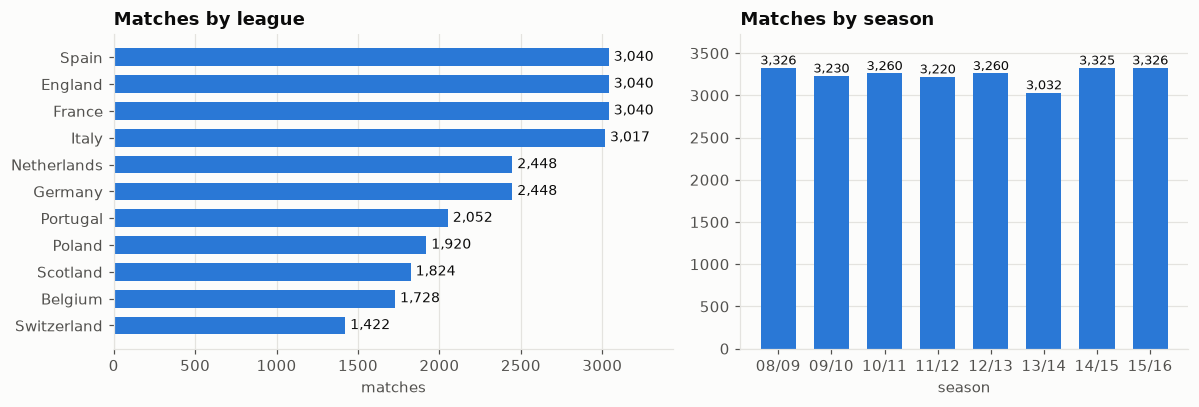

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
counts = matches["country"].value_counts().sort_values()
ax.barh(counts.index, counts.values, color=BLUE, height=0.66)
for i, v in enumerate(counts.values):
    ax.text(v + 30, i, f"{v:,}", va="center", color=INK, fontsize=9)
ax.set_xlim(0, counts.max() * 1.13)
ax.set_xlabel("matches")
ax.grid(axis="y", visible=False)
ax.set_title("Matches by league")

ax = axes[1]
per_season = matches.groupby("season").size()
ax.bar([s[2:4] + "/" + s[7:] for s in per_season.index], per_season.values, color=BLUE, width=0.66)
for i, v in enumerate(per_season.values):
    ax.text(i, v + 40, f"{v:,}", ha="center", color=INK, fontsize=8.5)
ax.set_ylim(0, per_season.max() * 1.12)
ax.set_xlabel("season")
ax.grid(axis="x", visible=False)
ax.set_title("Matches by season")

fig.tight_layout()
save(fig, "fig_3_1_matches_by_league_and_season.png")

### Figure 3.2 — Goals scored per match

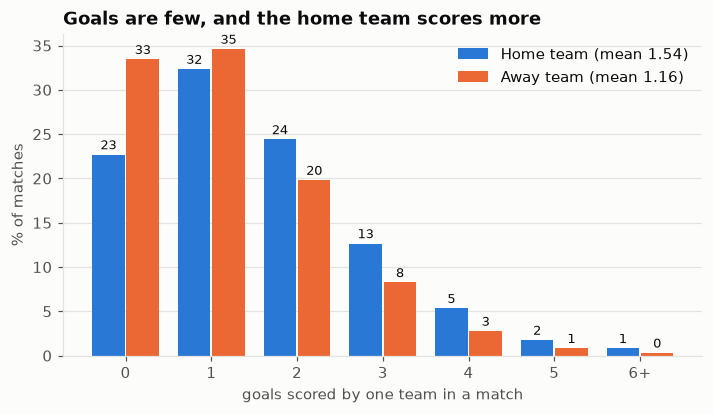

In [5]:
goals = np.arange(0, 7)
home = matches["home_team_goal"].clip(upper=6).value_counts(normalize=True).reindex(goals, fill_value=0) * 100
away = matches["away_team_goal"].clip(upper=6).value_counts(normalize=True).reindex(goals, fill_value=0) * 100

fig, ax = plt.subplots(figsize=(7.5, 3.8))
width = 0.38
ax.bar(goals - width / 2 - 0.01, home.values, width, color=BLUE, label=f"Home team (mean {matches['home_team_goal'].mean():.2f})")
ax.bar(goals + width / 2 + 0.01, away.values, width, color=ORANGE, label=f"Away team (mean {matches['away_team_goal'].mean():.2f})")
for x, (h, a) in enumerate(zip(home.values, away.values)):
    ax.text(x - width / 2 - 0.01, h + 0.6, f"{h:.0f}", ha="center", fontsize=8.5, color=INK)
    ax.text(x + width / 2 + 0.01, a + 0.6, f"{a:.0f}", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(goals, [*map(str, goals[:-1]), "6+"])
ax.set_xlabel("goals scored by one team in a match")
ax.set_ylabel("% of matches")
ax.grid(axis="x", visible=False)
ax.legend()
ax.set_title("Goals are few, and the home team scores more")
save(fig, "fig_3_2_goals_per_match.png")

### Figure 3.3 — How often each score occurs

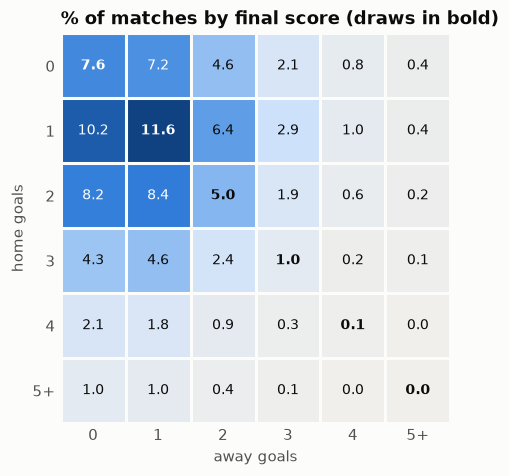

draw or one-goal margin: 62.3% of matches


In [6]:
grid = pd.crosstab(matches["home_team_goal"].clip(upper=5), matches["away_team_goal"].clip(upper=5), normalize=True) * 100
labels = ["0", "1", "2", "3", "4", "5+"]

fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.imshow(grid.values, cmap=SEQUENTIAL, vmin=0, vmax=grid.values.max())
for i in range(6):
    for j in range(6):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9,
                color="white" if v > grid.values.max() * 0.6 else INK, fontweight="bold" if i == j else "normal")
ax.set_xticks(range(6), labels)
ax.set_yticks(range(6), labels)
ax.set_xlabel("away goals")
ax.set_ylabel("home goals")
ax.set_xticks(np.arange(-0.5, 6), minor=True)
ax.set_yticks(np.arange(-0.5, 6), minor=True)
ax.grid(False)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("% of matches by final score (draws in bold)")
save(fig, "fig_3_3_score_grid.png")

margin = (matches["home_team_goal"] - matches["away_team_goal"]).abs()
print(f"draw or one-goal margin: {(margin <= 1).mean():.1%} of matches")

### Figure 3.4 — Data coverage by league

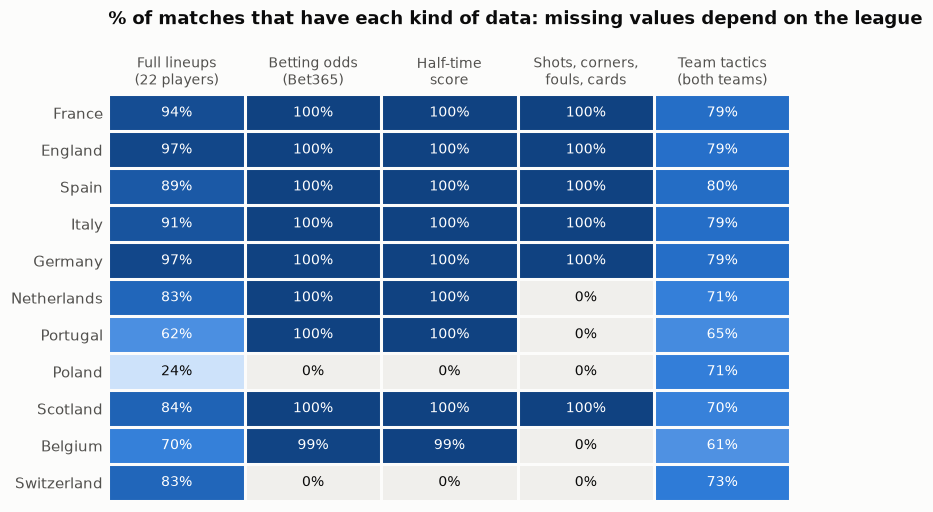

,Full lineups\n(22 players),Betting odds\n(Bet365),Half-time\nscore,"Shots, corners,\nfouls, cards",Team tactics\n(both teams)
country,,,,,
France,94.2,99.9,100.0,100.0,79.3
England,97.4,100.0,100.0,100.0,78.8
Spain,89.0,100.0,100.0,100.0,79.9
Italy,91.1,99.8,100.0,100.0,79.2
Germany,97.1,100.0,100.0,100.0,78.9
Netherlands,83.1,99.9,100.0,0.0,70.7
Portugal,62.4,99.6,100.0,0.0,64.7
Poland,24.4,0.0,0.0,0.0,71.4
Scotland,84.5,100.0,100.0,100.0,69.6


In [7]:
lineup_cols = [f"{side}_player_{k}" for side in ("home", "away") for k in range(1, 12)]
tactics = pd.read_parquet(DATA / "team_attributes.parquet")[["team_api_id", "date"]].sort_values("date")
first_snapshot = tactics.groupby("team_api_id")["date"].min()
has_tactics = (matches["home_team_api_id"].map(first_snapshot) <= matches["date"]) & \
              (matches["away_team_api_id"].map(first_snapshot) <= matches["date"])

coverage = pd.DataFrame({
    "league": matches["country"],
    "Full lineups\n(22 players)": matches[lineup_cols].notna().all(axis=1),
    "Betting odds\n(Bet365)": matches["B365H"].notna(),
    "Half-time\nscore": matches["h_ht_goals"].notna(),
    "Shots, corners,\nfouls, cards": matches["has_shot_stats"],
    "Team tactics\n(both teams)": has_tactics,
}).groupby("league").mean() * 100
coverage = coverage.loc[matches["country"].value_counts().index]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.imshow(coverage.values, cmap=SEQUENTIAL, vmin=0, vmax=100, aspect="auto")
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        v = coverage.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if v > 60 else INK)
ax.set_xticks(range(coverage.shape[1]), coverage.columns, fontsize=9)
ax.set_yticks(range(coverage.shape[0]), coverage.index)
ax.xaxis.tick_top()
ax.set_xticks(np.arange(-0.5, coverage.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, coverage.shape[0]), minor=True)
ax.grid(False)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("% of matches that have each kind of data: missing values depend on the league", pad=46)
save(fig, "fig_3_4_data_coverage.png")
coverage.round(1)

## 3.2 Match Results and Class Imbalance

### Table 3.3 — Class distribution

In [8]:
counts = matches["result"].value_counts().reindex(["H", "A", "D"])
class_table = pd.DataFrame({
    "result": [RESULT_NAME[r] for r in counts.index],
    "matches": counts.values,
    "share (%)": (counts.values / len(matches) * 100).round(1),
}, index=counts.index)
class_table.style.format({"matches": "{:,}", "share (%)": "{:.1f}"})

,result,matches,share (%)
result,,,
H,Home win,"11,917",45.9
A,Away win,"7,466",28.7
D,Draw,"6,596",25.4


### Figure 3.5 — Class distribution

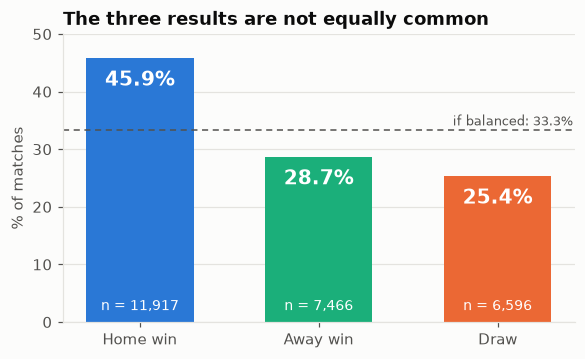

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.4))
order = ["H", "A", "D"]
share = matches["result"].value_counts(normalize=True).reindex(order) * 100
ax.bar([RESULT_NAME[r] for r in order], share.values, color=[RESULT_COLOR[r] for r in order], width=0.6)
for i, r in enumerate(order):
    ax.text(i, share[r] - 2.2, f"{share[r]:.1f}%", ha="center", va="top", fontsize=13, color="white", fontweight="bold")
    ax.text(i, 1.5, f"n = {counts[r]:,}", ha="center", va="bottom", fontsize=9, color="white")
ax.axhline(100 / 3, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(2.42, 100 / 3 + 0.8, "if balanced: 33.3%", ha="right", fontsize=8.5, color=MUTED)
ax.set_ylim(0, 50)
ax.set_ylabel("% of matches")
ax.grid(axis="x", visible=False)
ax.set_title("The three results are not equally common")
save(fig, "fig_3_5_class_distribution.png")

### Table 3.4 and Figure 3.6 — Results by league

In [10]:
by_league_result = (pd.crosstab(matches["country"], matches["result"], normalize="index")[["H", "D", "A"]] * 100)
by_league_result = by_league_result.sort_values("H", ascending=False)
by_league_result.rename(columns=RESULT_NAME).round(1)

result,Home win,Draw,Away win
country,,,
Spain,48.8,23.2,28.0
Netherlands,47.8,23.7,28.4
Belgium,46.9,24.6,28.5
Italy,46.6,26.4,27.0
England,45.7,25.8,28.5
Switzerland,45.7,24.3,30.0
Poland,45.3,27.3,27.3
Germany,45.2,24.4,30.4
France,44.7,28.3,27.0


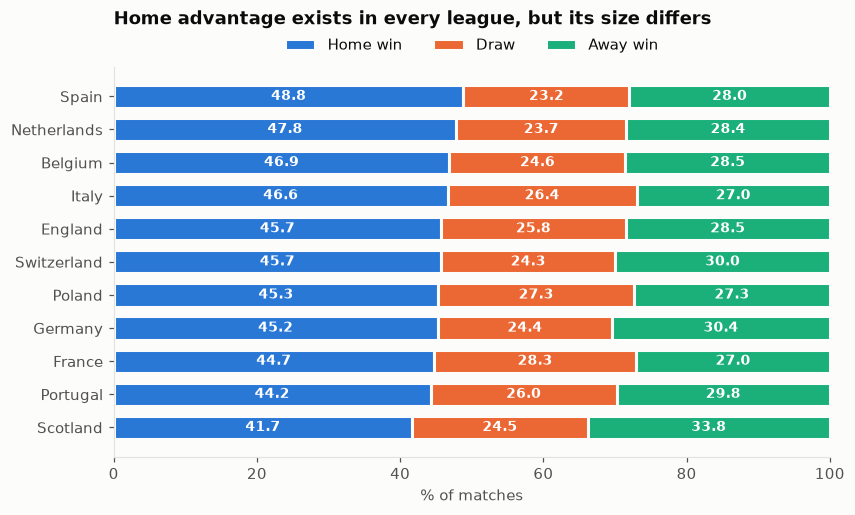

In [11]:
fig, ax = plt.subplots(figsize=(8.4, 4.6))
plot = by_league_result.iloc[::-1]
left = np.zeros(len(plot))
for r in ["H", "D", "A"]:
    ax.barh(plot.index, plot[r].values, left=left, color=RESULT_COLOR[r], height=0.7,
            edgecolor=SURFACE, linewidth=2, label=RESULT_NAME[r])
    for i, v in enumerate(plot[r].values):
        ax.text(left[i] + v / 2, i, f"{v:.1f}", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    left += plot[r].values
ax.set_xlim(0, 100)
ax.set_xlabel("% of matches")
ax.grid(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
ax.set_title("Home advantage exists in every league, but its size differs", pad=28)
save(fig, "fig_3_6_results_by_league.png")

### Table 3.5 and Figure 3.7 — Results by season

In [12]:
by_season = pd.crosstab(matches["season"], matches["result"], normalize="index")[["H", "D", "A"]] * 100
by_season.rename(columns=RESULT_NAME).round(1)

result,Home win,Draw,Away win
season,,,
2008/2009,47.1,25.0,27.9
2009/2010,47.4,25.2,27.4
2010/2011,46.6,25.7,27.6
2011/2012,46.5,25.4,28.1
2012/2013,44.3,26.2,29.5
2013/2014,46.3,24.3,29.4
2014/2015,44.9,25.6,29.5
2015/2016,43.9,25.7,30.4


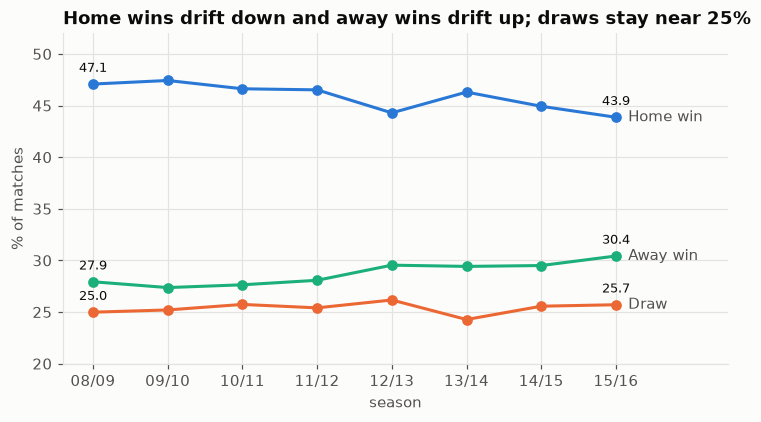

In [13]:
fig, ax = plt.subplots(figsize=(7.8, 3.9))
x = np.arange(len(by_season))
for r in ["H", "A", "D"]:
    ax.plot(x, by_season[r].values, marker="o", markersize=6, color=RESULT_COLOR[r])
    ax.annotate(RESULT_NAME[r], (x[-1], by_season[r].values[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=MUTED)
    for k in (0, len(x) - 1):
        ax.annotate(f"{by_season[r].values[k]:.1f}", (x[k], by_season[r].values[k]), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(x, [s[2:4] + "/" + s[7:] for s in by_season.index])
ax.set_xlim(-0.4, len(x) + 0.5)
ax.set_ylim(20, 52)
ax.set_xlabel("season")
ax.set_ylabel("% of matches")
ax.set_title("Home wins drift down and away wins drift up; draws stay near 25%")
save(fig, "fig_3_7_results_by_season.png")

### Table 3.6 — Class balance of the shared train / test split

In [14]:
with_split = matches.merge(split, on="match_api_id")
balance = pd.crosstab(with_split["split"], with_split["result"], normalize="index")[["H", "D", "A"]] * 100
balance = balance.rename(columns=RESULT_NAME).loc[["train", "test"]]
balance.insert(0, "matches", with_split["split"].value_counts())
balance.style.format({"matches": "{:,}", "Home win": "{:.1f}", "Draw": "{:.1f}", "Away win": "{:.1f}"})

result,matches,Home win,Draw,Away win
split,,,,
train,"18,185",46.0,25.2,28.8
test,"7,794",45.6,25.8,28.6


### Why accuracy alone is not enough

In [15]:
from sklearn.metrics import accuracy_score, f1_score

test = with_split[with_split["split"] == "test"]
always_home = np.full(len(test), "H")
pd.DataFrame({
    "accuracy": [accuracy_score(test["result"], always_home)],
    "macro F1": [f1_score(test["result"], always_home, average="macro")],
}, index=["always predict a home win (test split)"]).round(3)

,accuracy,macro F1
always predict a home win (test split),0.456,0.209
